In [7]:
from typing import TypedDict, Dict, List
from langgraph.graph import StateGraph, END, START
from random import randint

In [111]:
class StateAgent(TypedDict):
    player_name: str
    message: str
    guesses: List[int]
    attempt: int
    upperbound: int
    lowerbound: int

def setup_node(state: StateAgent) -> StateAgent:
    """ Sets up basic checks and greets the user with a message"""
    state["message"] = f"Hi there! {state['player_name']}"
    state['attempt'] = 0
    state['guesses'] = []
    return state

def guess_node(state: StateAgent)-> StateAgent:
    """Function guesses the number and returns if correct or counter is stacked"""
    state['guesses'].append(randint(state['lowerbound'], state['upperbound']))
    return state

def route_after_validate(state: StateAgent) -> StateAgent:
    """Validates the guess with the guessed number"""
    guessed_num = state["guesses"][-1]
    if  guessed_num == 12:
        print(f"Took this many guess {','.join(map(str, state['guesses']))} to find the 12")
        return "exit"
    elif state['attempt'] > 7:
        print(f"Guess limit exceeded {str(state['attempt'])}")
        return "exit"
    else:
        return "loop"

def validate_node(state:StateAgent) -> StateAgent:
    """Validates the guess with the guessed number"""
    state['attempt'] += 1
    guessed = state["guesses"][-1]
    if guessed > 12:
        state["upperbound"] = guessed - 1
    elif guessed < 12:
        state["lowerbound"] = guessed + 1
    print(
        f"Guess List: {state['guesses']}, \n"
        f"bounds now: lower {state.get('lowerbound')}, "
        f"upper {state.get('upperbound')}"
    )
    return state

graph = StateGraph(StateAgent)
graph.add_node("setup", setup_node)
graph.add_node("random_guess", guess_node)
graph.add_node("validate_guess", validate_node)
graph.add_edge(START, "setup")
graph.add_edge("setup", "random_guess")
graph.add_edge("random_guess", "validate_guess")
graph.add_conditional_edges(
    "validate_guess",
    route_after_validate,
    {
        "loop": "random_guess",
        "exit": END
    }
)
app = graph.compile()


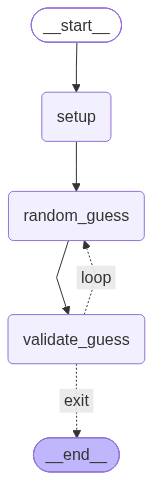

In [112]:
from IPython.display import display, Image
display(Image(app.get_graph().draw_mermaid_png()))

In [114]:
app.invoke({"player_name": "Yoki", "guesses":[], "attempt": 0, "lowerbound":5, "upperbound":20})

Guess List: [7], 
bounds now: lower 8, upper 20
Guess List: [7, 17], 
bounds now: lower 8, upper 16
Guess List: [7, 17, 10], 
bounds now: lower 11, upper 16
Guess List: [7, 17, 10, 14], 
bounds now: lower 11, upper 13
Guess List: [7, 17, 10, 14, 13], 
bounds now: lower 11, upper 12
Guess List: [7, 17, 10, 14, 13, 11], 
bounds now: lower 12, upper 12
Guess List: [7, 17, 10, 14, 13, 11, 12], 
bounds now: lower 12, upper 12
Took this many guess 7,17,10,14,13,11,12 to find the 12


{'player_name': 'Yoki',
 'message': 'Hi there! Yoki',
 'guesses': [7, 17, 10, 14, 13, 11, 12],
 'attempt': 7,
 'upperbound': 12,
 'lowerbound': 12}